# Build the bird species dataset

One end-to-end pipeline that replaces running `get_stations.py → get_movements.py → get_videos.py → get_frames.py → data_cleaner.py run` by hand:

1. Fetch all stations and their **validated** movements from the WieDiversIstMeinGarten API
2. Clean labels (multi-species videos are excluded)
3. Decide the classes from the support (videos, stations, station dominance) — weak birds are merged into `unknown_bird`, weak non-birds are dropped
4. Assign train/val/test (by station or by video) **before** downloading, so frames of one video/station never leak across splits
5. Sample videos (pilot: limited number per species), download them
6. Extract frames
7. Run the bird filter model: background frames become the `background` class (in the split of their video), unclear frames are rejected
8. Assemble `dataset/<split>/<class>/` and report statistics

Every step caches its output in `WORKDIR`, so the notebook can be re-run and only does new work.

In [ ]:
import os
import sys
import random
import shutil
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import cv2
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

DATA_DIR = Path.cwd()  # this notebook lives in data/
sys.path.insert(0, str(DATA_DIR))
from get_movements import BASE_URL, process_movements, fetch_with_retries

## 0. Configuration

In [ ]:
WORKDIR = DATA_DIR / "data_pilot"
USER_AGENT = ""                      # optional custom User-Agent for API requests
REFRESH_METADATA = False             # re-fetch stations/movements even if cached
SEED_MOVEMENTS_FROM = DATA_DIR / "data" / "movements.csv"  # reuse an existing movements.csv instead of crawling (None to disable)
LEGACY_VIDEO_DIR = DATA_DIR / "data" / "videos"            # reuse already downloaded videos (None to disable)
MOVEMENTS_PER_STATION = None         # API limit per station (None = API default)

# Pilot: max videos per species (None = all videos)
VIDEOS_PER_SPECIES = 20

# Class support thresholds (computed on the full metadata, not on the pilot sample)
MIN_VIDEOS = 30                      # min. number of single-species videos
MIN_STATIONS = 5                     # min. number of distinct stations
MAX_STATION_SHARE = 0.8              # max. share of videos coming from the single biggest station
NON_BIRD_CLASSES = {"homo_sapiens", "sciurus_vulgaris"}  # own class if supported, otherwise dropped
UNKNOWN_CLASS = "unknown_bird"
BACKGROUND_CLASS = "background"
MAX_VIDEOS_PER_STATION = 100         # cap videos per station and species (None = no cap); limits dominance of single stations
SPECIES_SYNONYMS = {"corvus_monedula": "coloeus_monedula", "human": "homo_sapiens"}

# Splits
SPLIT_BY = "station"                 # "station" (no station in two splits) or "video"
SPLITS = {"train": 0.7, "val": 0.2, "test": 0.1}
SPLIT_RESTARTS = 20                  # random restarts of the station split optimizer
SEED = 42

# Frame extraction
FRAME_RATE = 5                       # frames per second to look at
DIFF_THRESHOLD = 20                  # min. mean abs. difference to the last saved frame
FRAC_CHANGE = 0.2                    # min. fraction of changed pixels to the last saved frame
MIN_BRIGHTNESS, MAX_BRIGHTNESS, MIN_STD = 20, 235, 50  # skip dark/overexposed/low-contrast frames

# Bird filter (3-class ResNet18 from data_cleaner.py)
FILTER_MODEL = DATA_DIR / "acc98.98_e22_bird_filter_0729_1145.pth"
FILTER_IMG_SIZE = 960
FILTER_THRESHOLD = 90.0              # percent
FILTER_BATCH_SIZE = 8
MAX_BACKGROUND_PER_VIDEO = None      # cap background frames per video (None = keep all)

DOWNLOAD_WORKERS = 4
FRAME_WORKERS = os.cpu_count() or 4

assert abs(sum(SPLITS.values()) - 1) < 1e-6
WORKDIR.mkdir(parents=True, exist_ok=True)
VIDEO_DIR = WORKDIR / "videos"
FRAME_DIR = WORKDIR / "frames"
DATASET_DIR = WORKDIR / "dataset"
REJECTED_DIR = WORKDIR / "rejected"


def make_session():
    session = requests.Session()
    if USER_AGENT:
        session.headers.update({"User-Agent": USER_AGENT})
    adapter = requests.adapters.HTTPAdapter(pool_connections=20, pool_maxsize=20)
    session.mount("https://", adapter)
    session.mount("http://", adapter)
    return session

## 1. Stations

In [ ]:
STATIONS_CSV = WORKDIR / "stations.csv"


def fetch_stations(session):
    response = fetch_with_retries(session, f"{BASE_URL}/station")
    if response is None:
        raise RuntimeError("Could not fetch station list")
    rows = []
    for station in response.json():
        location = station.get("location") or {}
        last_movement = station.get("lastMovement") or {}
        rows.append({
            "station_id": station["station_id"],
            "name": station.get("name"),
            "lat": location.get("lat"),
            "lng": location.get("lng"),
            "last_movement_date": last_movement.get("createdAt"),
        })
    return pd.DataFrame(rows)


if REFRESH_METADATA or not STATIONS_CSV.exists():
    with make_session() as session:
        stations = fetch_stations(session)
    stations.to_csv(STATIONS_CSV, index=False)
stations = pd.read_csv(STATIONS_CSV)
print(f"{len(stations)} stations")

183 stations


## 2. Validated movements

In [ ]:
MOVEMENTS_CSV = WORKDIR / "movements.csv"


def fetch_movements(session, stations):
    rows = []
    for _, station in tqdm(stations.iterrows(), total=len(stations), desc="stations"):
        url = f"{BASE_URL}/movement/{station['station_id']}"
        if MOVEMENTS_PER_STATION:
            url += f"?movements={MOVEMENTS_PER_STATION}"
        response = fetch_with_retries(session, url)
        if response is None:
            print(f"[EXCEPTION] Station {station['station_id']} failed after retries")
            continue
        for mov in response.json() or []:
            processed = process_movements(station["station_id"], mov, validated_only=True)
            if processed:
                rows.append(processed)
        time.sleep(random.uniform(1.0, 2.5))  # be nice to the API
    return pd.DataFrame(rows)


if not MOVEMENTS_CSV.exists() and not REFRESH_METADATA and SEED_MOVEMENTS_FROM and Path(SEED_MOVEMENTS_FROM).exists():
    shutil.copy2(SEED_MOVEMENTS_FROM, MOVEMENTS_CSV)
    print(f"Seeded movements from {SEED_MOVEMENTS_FROM}")

if REFRESH_METADATA or not MOVEMENTS_CSV.exists():
    with make_session() as session:
        movements_raw = fetch_movements(session, stations)
    movements_raw.to_csv(MOVEMENTS_CSV, index=False)
movements_raw = pd.read_csv(MOVEMENTS_CSV)
print(f"{len(movements_raw)} validated movements from {movements_raw['station_id'].nunique()} stations")

42224 validated movements from 102 stations


## 3. Label cleaning
Videos validated with more than one species are excluded, because their frames cannot be labelled reliably.

In [ ]:
mov = movements_raw.dropna(subset=["validations", "video_link"]).drop_duplicates("mov_id").copy()
is_multi = mov["validations"].str.contains(";")
print(f"Excluding {is_multi.sum()} multi-species videos")
mov = mov[~is_multi].copy()
mov["species"] = mov["validations"].str.strip().str.lower().str.replace(" ", "_")
mov["species"] = mov["species"].replace(SPECIES_SYNONYMS)
mov["video_stem"] = mov["station_id"] + "_" + mov["mov_id"]
print(f"{len(mov)} single-species videos, {mov['species'].nunique()} species")

Excluding 792 multi-species videos
41432 single-species videos, 49 species


## 4. Support analysis and class map
A species becomes its own class if it has at least `MIN_VIDEOS` videos from at least `MIN_STATIONS` stations and no single station
contributes more than `MAX_STATION_SHARE` of its videos. Otherwise birds are merged into `unknown_bird` and non-birds are dropped.

In [ ]:
support = mov.groupby("species").agg(
    videos=("mov_id", "size"),
    stations=("station_id", "nunique"),
    top_station_share=("station_id", lambda s: s.value_counts(normalize=True).iloc[0]),
)
supported = (
    (support["videos"] >= MIN_VIDEOS)
    & (support["stations"] >= MIN_STATIONS)
    & (support["top_station_share"] <= MAX_STATION_SHARE)
)
is_bird = ~support.index.isin(NON_BIRD_CLASSES)
support["class"] = np.where(supported, support.index, np.where(is_bird, UNKNOWN_CLASS, None))
support["status"] = np.where(supported, "keep", np.where(is_bird, "unknown", "drop"))
support = support.sort_values("videos", ascending=False)
support.to_csv(WORKDIR / "class_map.csv")

mov["class"] = mov["species"].map(support["class"])  # map (not merge) so the cell can be re-run
mov = mov[mov["class"].notna()].copy()

print(support.to_markdown(floatfmt=".2f"))
unknown = mov[mov["class"] == UNKNOWN_CLASS]
print(f"\n{support['status'].eq('keep').sum()} species classes, "
      f"{UNKNOWN_CLASS}: {len(unknown)} videos / {unknown['station_id'].nunique()} stations "
      f"from {unknown['species'].nunique()} species")

| species                       |   videos |   stations |   top_station_share | class                         | status   |
|:------------------------------|---------:|-----------:|--------------------:|:------------------------------|:---------|
| parus_major                   |    14437 |         82 |                0.10 | parus_major                   | keep     |
| cyanistes_caeruleus           |     8844 |         80 |                0.07 | cyanistes_caeruleus           | keep     |
| passer_domesticus             |     4274 |         51 |                0.20 | passer_domesticus             | keep     |
| spinus_spinus                 |     3866 |          3 |                0.99 | unknown_bird                  | unknown  |
| erithacus_rubecula            |     1580 |         53 |                0.19 | erithacus_rubecula            | keep     |
| chloris_chloris               |     1576 |         31 |                0.47 | chloris_chloris               | keep     |
| prunella_modul

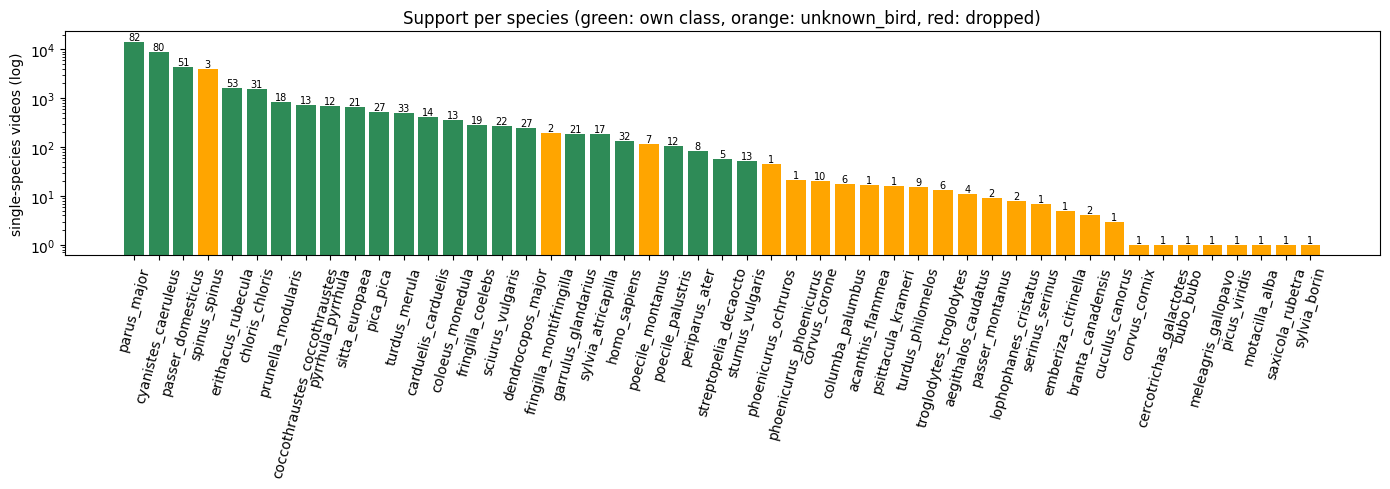

In [ ]:
colors = support["status"].map({"keep": "#2E8B57", "unknown": "#FFA500", "drop": "#B22222"})
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(support.index, support["videos"], color=colors)
ax.set_yscale("log")
ax.set_ylabel("single-species videos (log)")
ax.set_title("Support per species (green: own class, orange: unknown_bird, red: dropped)")
ax.tick_params(axis="x", rotation=75)
for x, (_, row) in enumerate(support.iterrows()):
    ax.text(x, row["videos"], str(row["stations"]), ha="center", va="bottom", fontsize=7)
plt.tight_layout()
plt.show()

### 4b. Cap videos per station
Keep at most `MAX_VIDEOS_PER_STATION` randomly chosen videos per station and species. Some stations contribute most of a class
(e.g. one station holds ~3,800 `spinus_spinus` videos of `unknown_bird`), which makes a balanced station split impossible and lets a
single background dominate the class. The class map above is computed before capping, so the cap only affects which videos are used.

In [ ]:
if MAX_VIDEOS_PER_STATION is not None:
    before = mov["class"].value_counts()
    mov = mov.sample(frac=1, random_state=SEED)
    mov = mov[mov.groupby(["station_id", "species"]).cumcount() < MAX_VIDEOS_PER_STATION].copy()
    after = mov["class"].value_counts()
    cap_report = pd.DataFrame({"videos_before": before, "videos_after": after}).sort_values("videos_before", ascending=False)
    cap_report["kept"] = cap_report["videos_after"] / cap_report["videos_before"]
    print(cap_report.to_markdown(floatfmt=".2f"))
    print()
    print(f"Kept {len(mov)} of {before.sum()} videos")

| class                         |   videos_before |   videos_after |   kept |
|:------------------------------|----------------:|---------------:|-------:|
| parus_major                   |        14437.00 |        5875.00 |   0.41 |
| cyanistes_caeruleus           |         8844.00 |        4765.00 |   0.54 |
| unknown_bird                  |         4399.00 |         603.00 |   0.14 |
| passer_domesticus             |         4274.00 |        2243.00 |   0.52 |
| erithacus_rubecula            |         1580.00 |        1299.00 |   0.82 |
| chloris_chloris               |         1576.00 |         903.00 |   0.57 |
| prunella_modularis            |          837.00 |         553.00 |   0.66 |
| coccothraustes_coccothraustes |          739.00 |         304.00 |   0.41 |
| pyrrhula_pyrrhula             |          708.00 |         322.00 |   0.45 |
| sitta_europaea                |          651.00 |         651.00 |   1.00 |
| pica_pica                     |          518.00 |         518.

## 5. Split assignment
Done on the metadata before anything is downloaded.
- `station`: every station belongs to exactly one split, so no background/camera leaks between splits. Because stations contain
  several classes, the assignment is optimized globally: a local search (moving single stations and swapping pairs of stations, with
  random restarts) minimizes the squared *relative* deviation of every class's split shares from the target shares, plus a penalty
  for classes that are missing in a split although they have enough stations.
- `video`: stratified random split of the videos per class.

Classes dominated by a single station (e.g. `spinus_spinus` inside `unknown_bird`) cannot be balanced by station assignment.

In [ ]:
def assign_station_splits(mov, ratios, seed, restarts=SPLIT_RESTARTS, missing_penalty=1.0):
    names = list(ratios)
    target = np.array([ratios[s] for s in names])
    counts = mov.pivot_table(index="station_id", columns="class", values="mov_id", aggfunc="size", fill_value=0)
    C = counts.to_numpy(float)                          # stations x classes (videos)
    totals = C.sum(0)
    n_stations, n_splits = C.shape[0], len(names)
    can_fill = (C > 0).sum(0) >= n_splits               # classes with enough stations to appear in every split

    def loss(S):                                        # S: classes x splits (videos)
        share = S / totals[:, None]
        missing = ((S == 0) & can_fill[:, None]).sum()
        return (((share - target) / target) ** 2).sum() + missing_penalty * missing

    rng = np.random.default_rng(seed)
    best_assignment, best_loss = None, np.inf
    for _ in range(restarts):
        a = rng.choice(n_splits, size=n_stations, p=target)
        S = np.stack([C[a == s].sum(0) for s in range(n_splits)], axis=1)
        current = loss(S)
        improved = True
        while improved:
            improved = False
            # Move single stations to another split
            for i in rng.permutation(n_stations):
                for q in range(n_splits):
                    p = a[i]
                    if q == p:
                        continue
                    S[:, p] -= C[i]
                    S[:, q] += C[i]
                    new = loss(S)
                    if new < current - 1e-12:
                        a[i], current, improved = q, new, True
                    else:
                        S[:, p] += C[i]
                        S[:, q] -= C[i]
            # Swap two stations of different splits
            for i in rng.permutation(n_stations):
                for j in range(n_stations):
                    p, q = a[i], a[j]
                    if p == q:
                        continue
                    d = C[i] - C[j]
                    S[:, p] -= d
                    S[:, q] += d
                    new = loss(S)
                    if new < current - 1e-12:
                        a[i], a[j], current, improved = q, p, new, True
                    else:
                        S[:, p] += d
                        S[:, q] -= d
        if current < best_loss:
            best_loss, best_assignment = current, a.copy()
    station_split = dict(zip(counts.index, [names[k] for k in best_assignment]))
    return mov["station_id"].map(station_split)


def assign_video_splits(mov, ratios, seed):
    split = pd.Series(index=mov.index, dtype=object)
    for _, group in mov.groupby("class"):
        idx = group.sample(frac=1, random_state=seed).index
        bounds = np.cumsum([0] + [round(r * len(idx)) for r in ratios.values()])
        bounds[-1] = len(idx)
        for name, lo, hi in zip(ratios, bounds[:-1], bounds[1:]):
            split.loc[idx[lo:hi]] = name
    return split


if SPLIT_BY == "station":
    mov["split"] = assign_station_splits(mov, SPLITS, SEED)
elif SPLIT_BY == "video":
    mov["split"] = assign_video_splits(mov, SPLITS, SEED)
else:
    raise ValueError(f"Unknown SPLIT_BY: {SPLIT_BY}")

split_table = pd.crosstab(mov["class"], mov["split"])[list(SPLITS)]
split_share = split_table.div(split_table.sum(axis=1), axis=0)
print(f"Target: {SPLITS}")
split_report = split_table.join(split_share, rsuffix="_share")
split_report["max_dev"] = (split_share - pd.Series(SPLITS)).abs().max(axis=1)
print(split_report.to_markdown(floatfmt=".2f"))
print(f"Mean max. deviation from target: {split_report['max_dev'].mean():.3f}")
print("Overall video shares:", mov["split"].value_counts(normalize=True).round(3).to_dict())
missing = split_table[(split_table == 0).any(axis=1)]
if len(missing):
    print(f"\n[WARN] Classes missing in a split:\n{missing}")
mov.to_csv(WORKDIR / "videos_split.csv", index=False)

Target: {'train': 0.7, 'val': 0.2, 'test': 0.1}
| class                         |   train |     val |   test |   train_share |   val_share |   test_share |   max_dev |
|:------------------------------|--------:|--------:|-------:|--------------:|------------:|-------------:|----------:|
| carduelis_carduelis           |  179.00 |   93.00 |  18.00 |          0.62 |        0.32 |         0.06 |      0.12 |
| chloris_chloris               |  638.00 |  185.00 |  80.00 |          0.71 |        0.20 |         0.09 |      0.01 |
| coccothraustes_coccothraustes |  168.00 |  110.00 |  26.00 |          0.55 |        0.36 |         0.09 |      0.16 |
| coloeus_monedula              |  250.00 |   60.00 |  41.00 |          0.71 |        0.17 |         0.12 |      0.03 |
| cyanistes_caeruleus           | 3212.00 |  947.00 | 606.00 |          0.67 |        0.20 |         0.13 |      0.03 |
| dendrocopos_major             |  170.00 |   43.00 |  27.00 |          0.71 |        0.18 |         0.11 |     

## 6. Video selection (pilot sampling)
Per species and split up to `VIDEOS_PER_SPECIES * share` videos, taken round-robin across stations for variety.

In [ ]:
def round_robin_sample(df, k, seed):
    df = df.sample(frac=1, random_state=seed)
    df = df.assign(_rank=df.groupby("station_id").cumcount())
    return df.sort_values("_rank", kind="stable").head(k).drop(columns="_rank")


if VIDEOS_PER_SPECIES is None:
    selected = mov.copy()
else:
    parts = []
    for (species, split), group in mov.groupby(["species", "split"]):
        k = max(1, round(VIDEOS_PER_SPECIES * SPLITS[split]))
        parts.append(round_robin_sample(group, k, SEED))
    selected = pd.concat(parts)
selected.to_csv(WORKDIR / "selected_videos.csv", index=False)
print(f"Selected {len(selected)} videos from {selected['station_id'].nunique()} stations")
print(pd.crosstab(selected["class"], selected["split"])[list(SPLITS)].to_markdown())

Selected 660 videos from 84 stations
| class                         |   train |   val |   test |
|:------------------------------|--------:|------:|-------:|
| carduelis_carduelis           |      14 |     4 |      2 |
| chloris_chloris               |      14 |     4 |      2 |
| coccothraustes_coccothraustes |      14 |     4 |      2 |
| coloeus_monedula              |      14 |     4 |      2 |
| cyanistes_caeruleus           |      14 |     4 |      2 |
| dendrocopos_major             |      14 |     4 |      2 |
| erithacus_rubecula            |      14 |     4 |      2 |
| fringilla_coelebs             |      14 |     4 |      2 |
| garrulus_glandarius           |      14 |     4 |      2 |
| homo_sapiens                  |      14 |     4 |      2 |
| parus_major                   |      14 |     4 |      2 |
| passer_domesticus             |      14 |     4 |      2 |
| periparus_ater                |      14 |     4 |      1 |
| pica_pica                     |      14 |     

## 7. Download videos

In [ ]:
VIDEO_DIR.mkdir(parents=True, exist_ok=True)
legacy_videos = {p.name: p for p in Path(LEGACY_VIDEO_DIR).rglob("*.mp4")} if LEGACY_VIDEO_DIR and Path(LEGACY_VIDEO_DIR).exists() else {}


def fetch_video(session, url, path):
    if path.exists():
        return "cached"
    if path.name in legacy_videos:
        shutil.copy2(legacy_videos[path.name], path)
        return "reused"
    tmp = path.with_suffix(".part")
    try:
        with session.get(url, stream=True, timeout=60) as response:
            if response.status_code != 200:
                return f"http {response.status_code}"
            with open(tmp, "wb") as f:
                for chunk in response.iter_content(chunk_size=1 << 16):
                    f.write(chunk)
        tmp.replace(path)
        return "downloaded"
    except Exception as e:
        tmp.unlink(missing_ok=True)
        return f"error {e}"


download_status = {}
with make_session() as session, ThreadPoolExecutor(max_workers=DOWNLOAD_WORKERS) as ex:
    futures = {
        ex.submit(fetch_video, session, row.video_link, VIDEO_DIR / f"{row.video_stem}.mp4"): row.video_stem
        for row in selected.itertuples()
    }
    for fut in tqdm(as_completed(futures), total=len(futures), desc="videos"):
        download_status[futures[fut]] = fut.result()

status = pd.Series(download_status)
print(status.str.split().str[0].value_counts().to_string())
failed = status[~status.isin(["cached", "reused", "downloaded"])]
if len(failed):
    print(f"[WARN] {len(failed)} downloads failed:\n{failed.head(20).to_string()}")

videos:   0%|          | 0/660 [00:00<?, ?it/s]

downloaded    660


## 8. Frame extraction
Same logic as `get_frames.py`: look at `FRAME_RATE` frames per second, skip dark/overexposed/low-contrast frames and frames too similar
to the last saved one. Frames of a video go to `frames/<station>_<mov>/`, written to a `.tmp` folder first so interrupted videos are redone.

In [ ]:
def extract_frames(video_path, out_root):
    stem = video_path.stem
    out_dir = out_root / stem
    if out_dir.exists():
        return stem, len(list(out_dir.glob("*.jpg"))), "cached"
    tmp_dir = out_root / f"{stem}.tmp"
    shutil.rmtree(tmp_dir, ignore_errors=True)
    tmp_dir.mkdir(parents=True)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        shutil.rmtree(tmp_dir, ignore_errors=True)
        return stem, 0, "could not open"
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    frame_interval = max(int(round(fps / FRAME_RATE)), 1) if FRAME_RATE else 1

    frame_idx = saved = 0
    prev = None
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if frame_idx % frame_interval == 0:
            blurred = cv2.GaussianBlur(frame, (3, 3), 0)  # cancel out sensor noise
            mean, std = blurred.mean(), blurred.std()
            keep = MIN_BRIGHTNESS <= mean <= MAX_BRIGHTNESS and std >= MIN_STD
            if keep and prev is not None:
                diff = cv2.absdiff(blurred, prev)
                fraction_changed = np.mean(cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY) > 10)
                keep = fraction_changed >= FRAC_CHANGE and diff.mean() >= DIFF_THRESHOLD
            if keep:
                cv2.imwrite(str(tmp_dir / f"{stem}_{saved:03d}.jpg"), frame)
                saved += 1
                prev = blurred
        frame_idx += 1
    cap.release()
    tmp_dir.rename(out_dir)
    return stem, saved, "extracted"


FRAME_DIR.mkdir(parents=True, exist_ok=True)
videos_on_disk = [VIDEO_DIR / f"{stem}.mp4" for stem in selected["video_stem"] if (VIDEO_DIR / f"{stem}.mp4").exists()]
frame_log = []
with ThreadPoolExecutor(max_workers=FRAME_WORKERS) as ex:
    futures = [ex.submit(extract_frames, p, FRAME_DIR) for p in videos_on_disk]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="frames"):
        frame_log.append(fut.result())
frame_log = pd.DataFrame(frame_log, columns=["video_stem", "frames", "status"])
print(frame_log["status"].value_counts().to_string())
print(f"{frame_log['frames'].sum()} frames, {frame_log['frames'].eq(0).sum()} videos without frames")

frames:   0%|          | 0/660 [00:00<?, ?it/s]

status
extracted    660
6914 frames, 27 videos without frames


## 9. Bird filter
The 3-class model (`background` / `unclear` / `bird`) from `data_cleaner.py` scores every frame. Predictions are cached in `frames.csv`,
so only new frames are scored on a re-run.

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from data_cleaner import load_model, make_transform, CLASS_TO_IDX

FRAMES_CSV = WORKDIR / "frames.csv"


class FrameDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        return self.transform(Image.open(self.paths[idx]).convert("RGB"))


frame_rows = []
for stem in selected["video_stem"]:
    for p in sorted((FRAME_DIR / stem).glob("*.jpg")) if (FRAME_DIR / stem).exists() else []:
        frame_rows.append({"frame": p.name, "video_stem": stem})
frames = pd.DataFrame(frame_rows, columns=["frame", "video_stem"])

prob_cols = ["p_background", "p_unclear", "p_bird"]
cached = pd.read_csv(FRAMES_CSV)[["frame", *prob_cols]] if FRAMES_CSV.exists() else pd.DataFrame(columns=["frame", *prob_cols])
frames = frames.merge(cached, on="frame", how="left")
todo = frames[frames["p_bird"].isna()]
print(f"{len(frames)} frames, {len(todo)} to score")

if len(todo):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = load_model(FILTER_MODEL, device)
    paths = [FRAME_DIR / stem / name for name, stem in zip(todo["frame"], todo["video_stem"])]
    loader = DataLoader(FrameDataset(paths, make_transform(FILTER_IMG_SIZE)), batch_size=FILTER_BATCH_SIZE, num_workers=0)
    probs = []
    with torch.no_grad():
        for x in tqdm(loader, desc=f"filter ({device})"):
            probs.append(torch.softmax(model(x.to(device)), dim=1).cpu())
    probs = torch.cat(probs).numpy() * 100
    order = [CLASS_TO_IDX[c] for c in ("background", "unclear", "bird")]
    frames.loc[todo.index, prob_cols] = probs[:, order]

frames[prob_cols] = frames[prob_cols].astype(float)
frames["filter_label"] = np.select(
    [frames["p_background"] >= FILTER_THRESHOLD, frames["p_unclear"] >= FILTER_THRESHOLD],
    ["background", "unclear"],
    "bird",
)
frames = frames.merge(selected[["video_stem", "station_id", "mov_id", "species", "class", "split"]], on="video_stem")
frames.to_csv(FRAMES_CSV, index=False)
print(pd.crosstab(frames["class"], frames["filter_label"]).to_markdown())

6914 frames, 6914 to score


filter (cuda):   0%|          | 0/865 [00:00<?, ?it/s]

| class                         |   background |   bird |   unclear |
|:------------------------------|-------------:|-------:|----------:|
| carduelis_carduelis           |           13 |    101 |         8 |
| chloris_chloris               |           15 |    117 |         1 |
| coccothraustes_coccothraustes |           23 |    319 |         0 |
| coloeus_monedula              |           67 |    379 |        13 |
| cyanistes_caeruleus           |           22 |    100 |         1 |
| dendrocopos_major             |           26 |    261 |         2 |
| erithacus_rubecula            |           17 |    118 |         1 |
| fringilla_coelebs             |           17 |    203 |         3 |
| garrulus_glandarius           |           57 |    258 |         6 |
| homo_sapiens                  |           21 |    114 |         0 |
| parus_major                   |           18 |     89 |         1 |
| passer_domesticus             |           19 |    216 |         0 |
| periparus_ater    

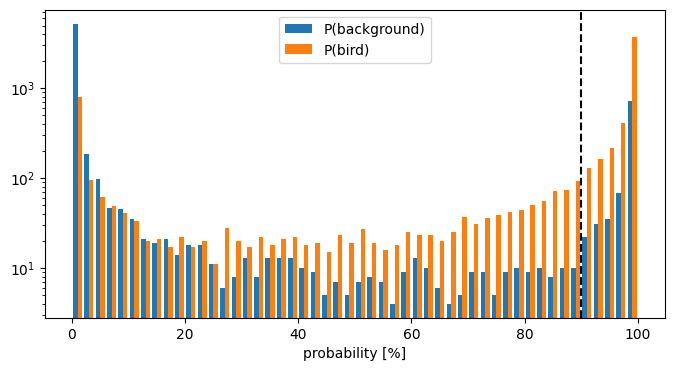

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([frames["p_background"], frames["p_bird"]], bins=50, label=["P(background)", "P(bird)"])
ax.axvline(FILTER_THRESHOLD, color="k", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("probability [%]")
ax.legend()
plt.show()

## 10. Assemble the dataset
`dataset/` is rebuilt from scratch from `frames.csv`. Bird frames go to their class, background frames to `background` in the split of
their video, unclear frames to `rejected/unclear/<class>/` for inspection. Files are hard-linked if possible (no extra disk space).

In [ ]:
def link_or_copy(src, dst):
    dst.parent.mkdir(parents=True, exist_ok=True)
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)


frames["target"] = np.where(frames["filter_label"] == "background", BACKGROUND_CLASS, frames["class"])
frames.loc[frames["filter_label"] == "unclear", "target"] = None

if MAX_BACKGROUND_PER_VIDEO is not None:
    is_bg = frames["target"] == BACKGROUND_CLASS
    keep_bg = frames[is_bg].groupby("video_stem", group_keys=False).apply(
        lambda g: g.sample(min(len(g), MAX_BACKGROUND_PER_VIDEO), random_state=SEED)).index
    frames.loc[is_bg & ~frames.index.isin(keep_bg), "target"] = None

for d in (DATASET_DIR, REJECTED_DIR):
    shutil.rmtree(d, ignore_errors=True)

cols = ["video_stem", "frame", "split", "class", "target", "filter_label"]
for stem, name, split, cls, target, label in tqdm(frames[cols].itertuples(index=False), total=len(frames), desc="assemble"):
    src = FRAME_DIR / stem / name
    if pd.notna(target):
        link_or_copy(src, DATASET_DIR / split / target / name)
    elif label == "unclear":
        link_or_copy(src, REJECTED_DIR / "unclear" / cls / name)

frames.to_csv(WORKDIR / "dataset_manifest.csv", index=False)
print(f"Wrote {frames['target'].notna().sum()} frames to {DATASET_DIR}")

assemble:   0%|          | 0/6914 [00:00<?, ?it/s]

Wrote 6761 frames to c:\Users\Jan Stenkamp\Documents\Birdiary\TinyBirdiary\bird-species-classification\data\data_pilot\dataset


## 11. Report

In [ ]:
ds = frames[frames["target"].notna()]
images = pd.crosstab(ds["target"], ds["split"])[list(SPLITS)]
videos = ds.groupby(["target", "split"])["video_stem"].nunique().unstack(fill_value=0)[list(SPLITS)]
stations_ = ds.groupby(["target", "split"])["station_id"].nunique().unstack(fill_value=0)[list(SPLITS)]
report = pd.concat({"images": images, "videos": videos, "stations": stations_}, axis=1).fillna(0).astype(int)
report.columns = [f"{m}_{s}" for m, s in report.columns]
print(report.to_markdown())
print("\nOverall:", ds["split"].value_counts().reindex(list(SPLITS)).to_dict())

# Leakage checks
station_multi = ds.groupby("station_id")["split"].nunique()
video_multi = ds.groupby("video_stem")["split"].nunique()
print(f"\nStations in more than one split: {(station_multi > 1).sum()} (expected 0 for SPLIT_BY='station')")
print(f"Videos in more than one split:   {(video_multi > 1).sum()} (expected 0)")
missing = images[(images == 0).any(axis=1)]
print(f"Classes missing in a split:      {list(missing.index)}")
nested = [p for p in DATASET_DIR.glob("*/*/*") if p.is_dir()]
print(f"Nested folders inside classes:   {len(nested)} (expected 0)")

from torchvision.datasets import ImageFolder
print(f"\nImageFolder classes (train): {ImageFolder(DATASET_DIR / 'train').classes}")

| target                        |   images_train |   images_val |   images_test |   videos_train |   videos_val |   videos_test |   stations_train |   stations_val |   stations_test |
|:------------------------------|---------------:|-------------:|--------------:|---------------:|-------------:|--------------:|-----------------:|---------------:|----------------:|
| background                    |            612 |          178 |            81 |            286 |           94 |            38 |               51 |             13 |               9 |
| carduelis_carduelis           |             66 |           34 |             1 |             10 |            3 |             1 |                7 |              2 |               1 |
| chloris_chloris               |             71 |           23 |            23 |             13 |            2 |             2 |               13 |              2 |               2 |
| coccothraustes_coccothraustes |            202 |           81 |            36 

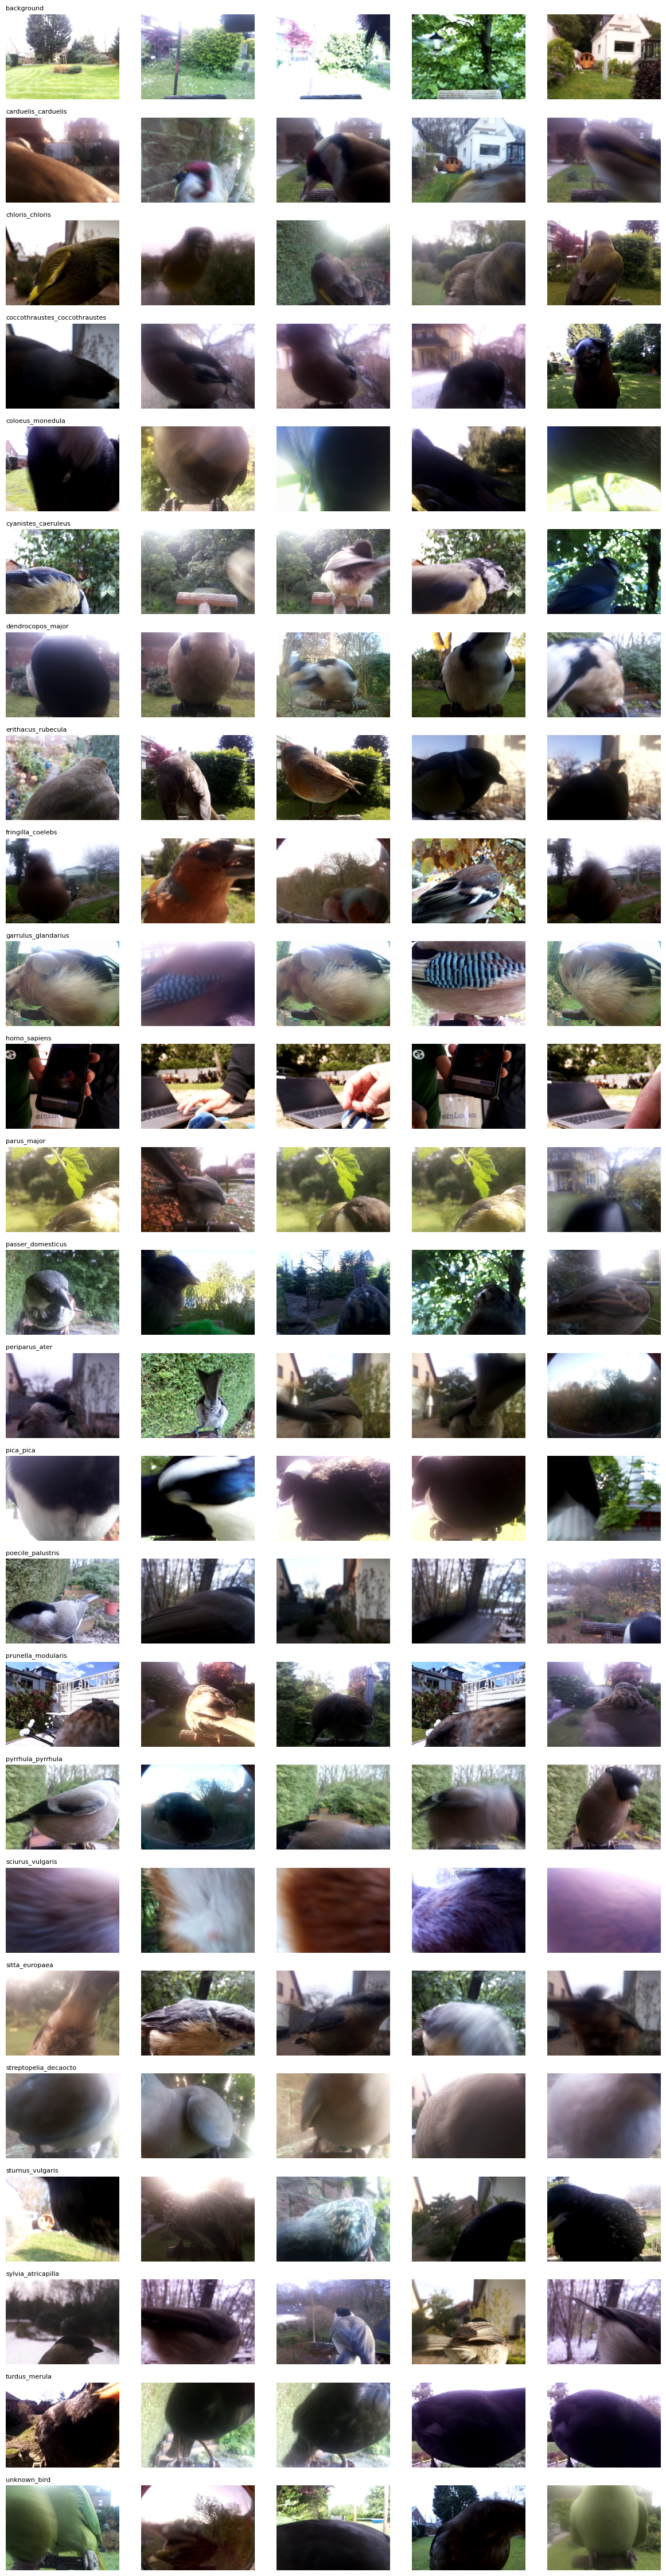

In [ ]:
def show_samples(split="train", per_class=5, seed=SEED):
    classes = sorted(ds["target"].unique())
    fig, axes = plt.subplots(len(classes), per_class, figsize=(2.4 * per_class, 1.8 * len(classes)))
    for r, cls in enumerate(classes):
        sub = ds[(ds["target"] == cls) & (ds["split"] == split)]
        sub = sub.sample(min(per_class, len(sub)), random_state=seed)
        for c in range(per_class):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(sub):
                row = sub.iloc[c]
                img = cv2.imread(str(FRAME_DIR / row["video_stem"] / row["frame"]))
                ax.imshow(cv2.cvtColor(cv2.resize(img, (240, 180)), cv2.COLOR_BGR2RGB))
            if c == 0:
                ax.set_title(cls, fontsize=8, loc="left")
    plt.tight_layout()
    plt.show()


show_samples("train")